# Image retrieval evaluation

Embed **only the VLM visual description for each image** with Gemini Embedding 2, the highest-scoring text embedding model. At retrieval, search the full image corpus using description similarity. PDF names remain vector metadata for reporting; the gold dataset is used only to score retrieved image IDs.

## 1. Setup

In [1]:
import gc
import importlib
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "SheCraft" / "ai-service", cwd / "ai-service"]
PROJECT_ROOT = next((p for p in candidates if (p / "src/rag/scripts").is_dir() and (p / "rag_documents").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the ai-service project root.")
RAG_SRC_DIR = PROJECT_ROOT / "src" / "rag"
if str(RAG_SRC_DIR) not in sys.path:
    sys.path.insert(0, str(RAG_SRC_DIR))

image_embeddings = importlib.reload(importlib.import_module("scripts.10_image_embeddings"))
retrieval = importlib.reload(importlib.import_module("scripts.7_retrieval"))
IMAGE_MODEL = image_embeddings.DEFAULT_CONTEXT_MODEL
TOP_K = 5
ARTIFACT_ROOT = PROJECT_ROOT / "data/rag/processed_documents"
EMBEDDING_ROOT = PROJECT_ROOT / "data/rag/embeddings/image_vlm_descriptions"
EVALUATION_DIR = PROJECT_ROOT / "data/rag/evaluations"
CASES_FILE = EVALUATION_DIR / "image_retrieval_benchmark_100.json"
RESULTS_FILE = EVALUATION_DIR / "image_retrieval_results.json"
print("Embedding model:", IMAGE_MODEL, "| provider: Gemini API")
print("Retrieval: VLM-description similarity over the full image corpus")

Embedding model: gemini-embedding-2 | provider: Gemini API
Retrieval: VLM-description similarity over the full image corpus


## 2. Load images and the image gold dataset

In [2]:
records = image_embeddings.load_image_records(processed_root=ARTIFACT_ROOT)
records_by_id = {record["image_id"]: record for record in records}
benchmark = json.loads(CASES_FILE.read_text(encoding="utf-8"))
evaluation_cases = [case for case in benchmark["cases"] if case.get("annotation_status") == "reviewed" and case.get("expected_image_ids")]
if not evaluation_cases:
    raise ValueError("The image gold dataset has no reviewed image-ID labels.")

image_ids = set(records_by_id)
pdf_names = {record["file_name"] for record in records}
for case in evaluation_cases:
    missing_ids = sorted(set(case["expected_image_ids"]) - image_ids)
    if missing_ids:
        raise ValueError(f"{case['id']} references unknown image IDs: {missing_ids}")

print("Extracted images:", len(records))
print("Gold evaluation questions:", len(evaluation_cases))
print("Languages:", benchmark.get("languages", {}))
print("PDFs in corpus:", len(pdf_names))

Extracted images: 307
Gold evaluation questions: 93
Languages: {'en': 56, 'ar': 19, 'fr': 18}
PDFs in corpus: 38


## 3. Embed VLM descriptions only (cached)

In [3]:
embedding_result = image_embeddings.get_or_create_image_embeddings(
    records,
    output_root=EMBEDDING_ROOT,
    context_model_name=IMAGE_MODEL,
    local_files_only=True,
    force=False,
)
context_embeddings = embedding_result["context_embeddings"]
print("Embedding cache hit:", embedding_result["cache_hit"])
print("Embedded text: VLM visual descriptions only")

gemini-embedding-2 checkpoint saved: batch 1/307 (1/307 texts)
gemini-embedding-2 checkpoint saved: batch 2/307 (2/307 texts)
gemini-embedding-2 checkpoint saved: batch 3/307 (3/307 texts)
gemini-embedding-2 checkpoint saved: batch 4/307 (4/307 texts)
gemini-embedding-2 checkpoint saved: batch 5/307 (5/307 texts)
gemini-embedding-2 checkpoint saved: batch 6/307 (6/307 texts)
gemini-embedding-2 checkpoint saved: batch 7/307 (7/307 texts)
gemini-embedding-2 checkpoint saved: batch 8/307 (8/307 texts)
gemini-embedding-2 checkpoint saved: batch 9/307 (9/307 texts)
gemini-embedding-2 checkpoint saved: batch 10/307 (10/307 texts)
gemini-embedding-2 checkpoint saved: batch 11/307 (11/307 texts)
gemini-embedding-2 checkpoint saved: batch 12/307 (12/307 texts)
gemini-embedding-2 checkpoint saved: batch 13/307 (13/307 texts)
gemini-embedding-2 checkpoint saved: batch 14/307 (14/307 texts)
gemini-embedding-2 checkpoint saved: batch 15/307 (15/307 texts)
gemini-embedding-2 checkpoint saved: batch 

## 4. Load the Gemini query embedder

In [4]:
image_model = image_embeddings.load_image_query_model(
    IMAGE_MODEL,
    cache_root=PROJECT_ROOT / "data/rag/embeddings/image_query_embeddings",
    env_file=PROJECT_ROOT / ".env",
)
print("Loaded query embedder:", IMAGE_MODEL)

Loaded query embedder: gemini-embedding-2


## 5. Retrieve from all images and score against gold image IDs

In [5]:
def first_relevant_rank(retrieved_ids, expected_ids):
    expected = set(expected_ids)
    return next((rank for rank, image_id in enumerate(retrieved_ids, start=1) if image_id in expected), None)

case_rows = []
for case in evaluation_cases:
    results = retrieval.retrieve_images(
        case["query"], method="context_dense", model=image_model,
        model_name=IMAGE_MODEL, top_k=TOP_K,
        context_embeddings=context_embeddings, image_records=records,
    )
    retrieved_ids = results["image_id"].tolist() if not results.empty else []
    expected_ids = list(case["expected_image_ids"])
    rank = first_relevant_rank(retrieved_ids, expected_ids)
    relevant_count = sum(image_id in set(expected_ids) for image_id in retrieved_ids)
    case_rows.append({
        "case_id": case["id"], "language": case["language"],
        "query_scope": case["query_scope"], "query": case["query"],
        "expected_image_ids": expected_ids, "retrieved_image_ids": retrieved_ids,
        "retrieved_pdfs": results["file_name"].tolist() if not results.empty else [],
        "first_relevant_rank": rank, "hit_at_1": rank == 1,
        "hit_at_5": rank is not None and rank <= TOP_K,
        "recall_at_5": relevant_count / len(expected_ids),
        "precision_at_5": relevant_count / max(1, len(retrieved_ids)),
        "mrr_at_5": 1 / rank if rank is not None and rank <= TOP_K else 0.0,
    })
case_results = pd.DataFrame(case_rows)

def summarize(group):
    return pd.Series({
        "cases": len(group), "Hit@1": group["hit_at_1"].mean(),
        "Hit@5": group["hit_at_5"].mean(), "Recall@5": group["recall_at_5"].mean(),
        "Precision@5": group["precision_at_5"].mean(), "MRR@5": group["mrr_at_5"].mean(),
    })

overall_metrics = summarize(case_results).to_frame().T
def grouped_summary(column):
    rows = []
    for value, group in case_results.groupby(column):
        rows.append({column: value, **summarize(group).to_dict()})
    return pd.DataFrame(rows).set_index(column)

language_metrics = grouped_summary("language")
scope_metrics = grouped_summary("query_scope")
print("Overall:")
display(overall_metrics.round(4))
print("By language:")
display(language_metrics.round(4))
print("By query scope:")
display(scope_metrics.round(4))

payload = {
    "schema_version": 1, "embedding_model": IMAGE_MODEL,
    "embedded_text": "VLM visual description only",
    "retrieval_method": "dense similarity over all images; PDF name is metadata only",
    "top_k": TOP_K, "gold_dataset": CASES_FILE.name,
    "case_count": len(case_results),
    "overall_metrics": json.loads(overall_metrics.to_json(orient="records")),
    "metrics_by_language": json.loads(language_metrics.reset_index().to_json(orient="records")),
    "metrics_by_query_scope": json.loads(scope_metrics.reset_index().to_json(orient="records")),
    "case_results": case_rows,
}
RESULTS_FILE.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved image retrieval evaluation results.")

gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 texts)
gemini-embedding-2 checkpoint saved: batch 1/1 (1/1 text

,cases,Hit@1,Hit@5,Recall@5,Precision@5,MRR@5
0,93.0,0.5914,0.7957,0.3929,0.3892,0.6747


By language:


,cases,Hit@1,Hit@5,Recall@5,Precision@5,MRR@5
language,,,,,,
ar,19.0,0.7895,0.8421,0.4450,0.4316,0.8158
en,56.0,0.6071,0.8214,0.3890,0.4179,0.6935
fr,18.0,0.3333,0.6667,0.3497,0.2556,0.4676


By query scope:


,cases,Hit@1,Hit@5,Recall@5,Precision@5,MRR@5
query_scope,,,,,,
cross_pdf,19.0,0.5263,0.8421,0.2389,0.4316,0.6447
single_pdf,74.0,0.6081,0.7838,0.4324,0.3784,0.6824


Saved image retrieval evaluation results.


## 6. Inspect retrieved results

### image_003: How should a jeweler measure a finger for an accurate ring size?

Expected image IDs: ['Ring Size Guide-5ada662598a071ee', 'Ring Size Guide-616cb72dc1a458f6']


**1. Relevant** - `Ring Size Guide-5ada662598a071ee` | Ring Size Guide.pdf | pages [3]

This image shows a ring sizer set featuring a collection of graduated metal ring gauges linked together on a wire loop with a circular fastener. The silver-colored metal rings vary in size, with numbers visible on the sides, including "24.0". The object is isolated against a plain white background.

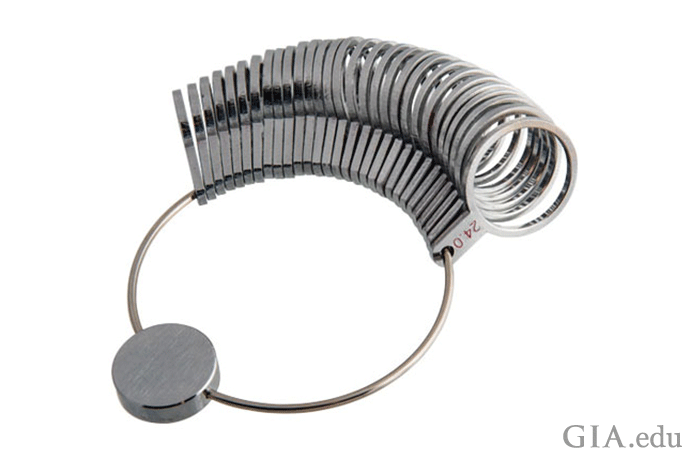

**2. Not labeled relevant** - `jewelry_settings_bench_guide-b7cc9215bf515a5c` | jewelry_settings_bench_guide.pdf | pages [4]

An illustration of a ring setting holding a gemstone is shown. The jewelry is made of a metallic material, and the diamond is faceted. The metal has a reflective, silver appearance. The design includes prongs with rounded tips that secure the central stone.

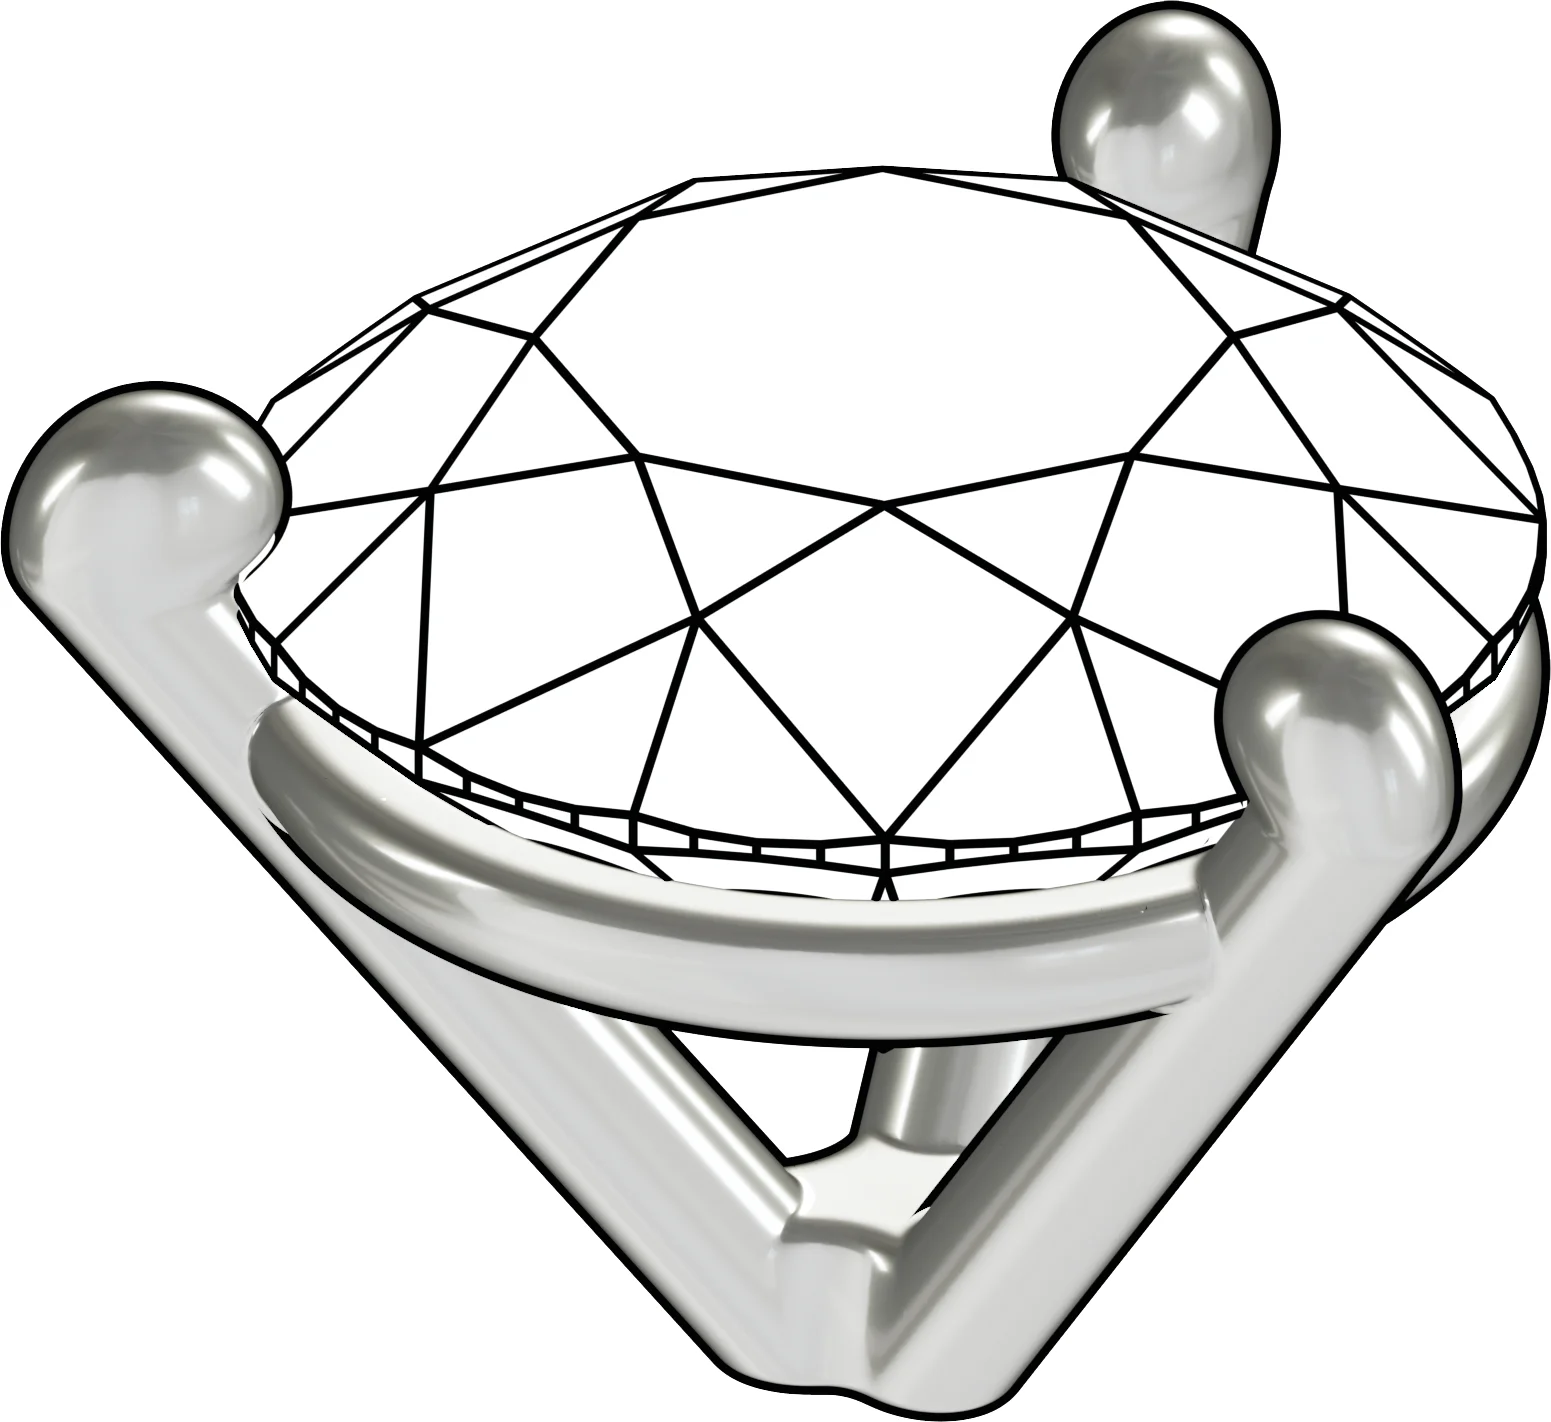

**3. Not labeled relevant** - `ring_metals_everyday_wear-7396b4eb56a2fb9b` | ring_metals_everyday_wear.pdf | pages [1]

This close-up shot shows a person's hand wearing a gold engagement ring with a round-cut solitaire diamond on the ring finger. Another hand is gently holding or touching the fingers, suggesting an intimate moment of proposal or affection. The soft lighting and neutral background highlight the sparkle of the diamond and the warm tones of the gold band and skin.

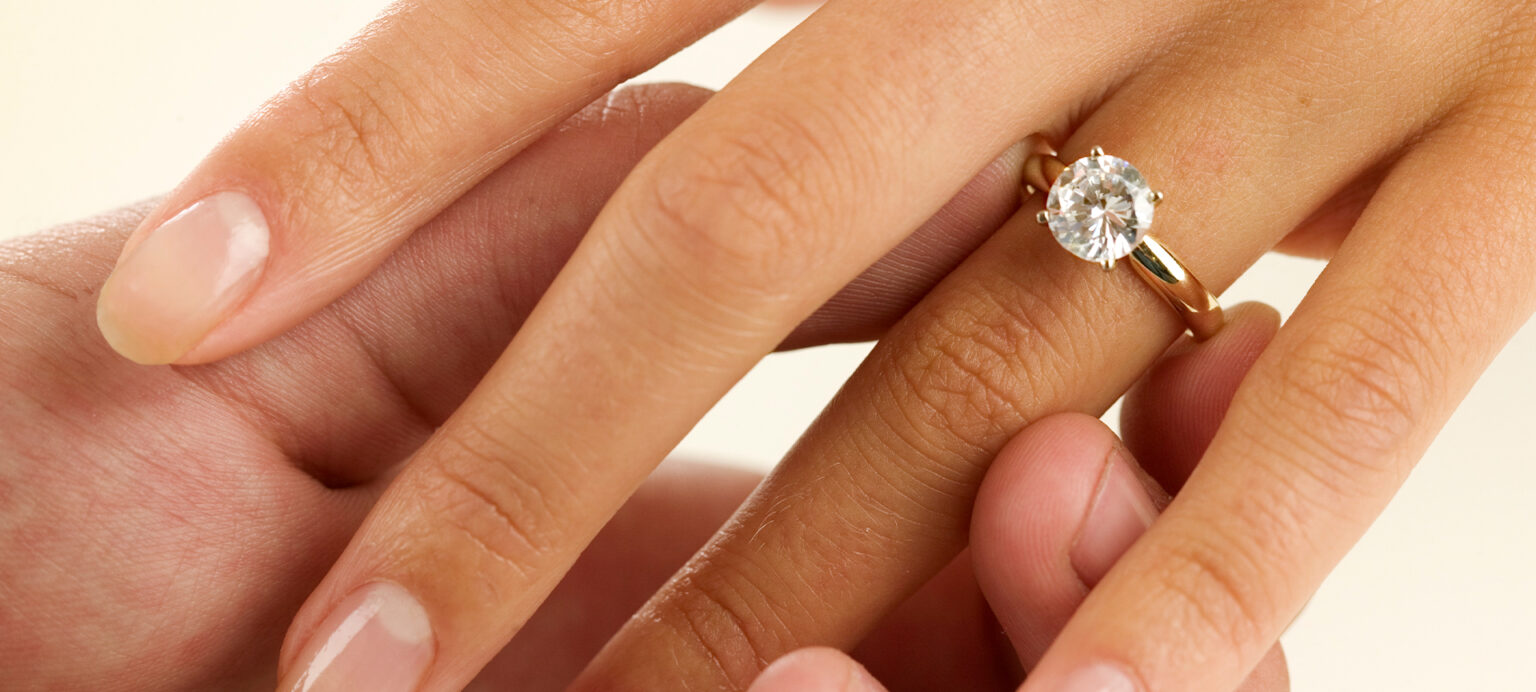

**4. Not labeled relevant** - `jewelry_settings_bench_guide-6f613d6be9069794` | jewelry_settings_bench_guide.pdf | pages [2]

This close-up shot captures a jeweler at work, holding a marquise-cut diamond with silver tweezers above a partially set white gold ring secured in a clamp. The setting features a gallery accented with small pave diamonds. The backdrop is a smooth, out-of-focus gradient of brown and gold.

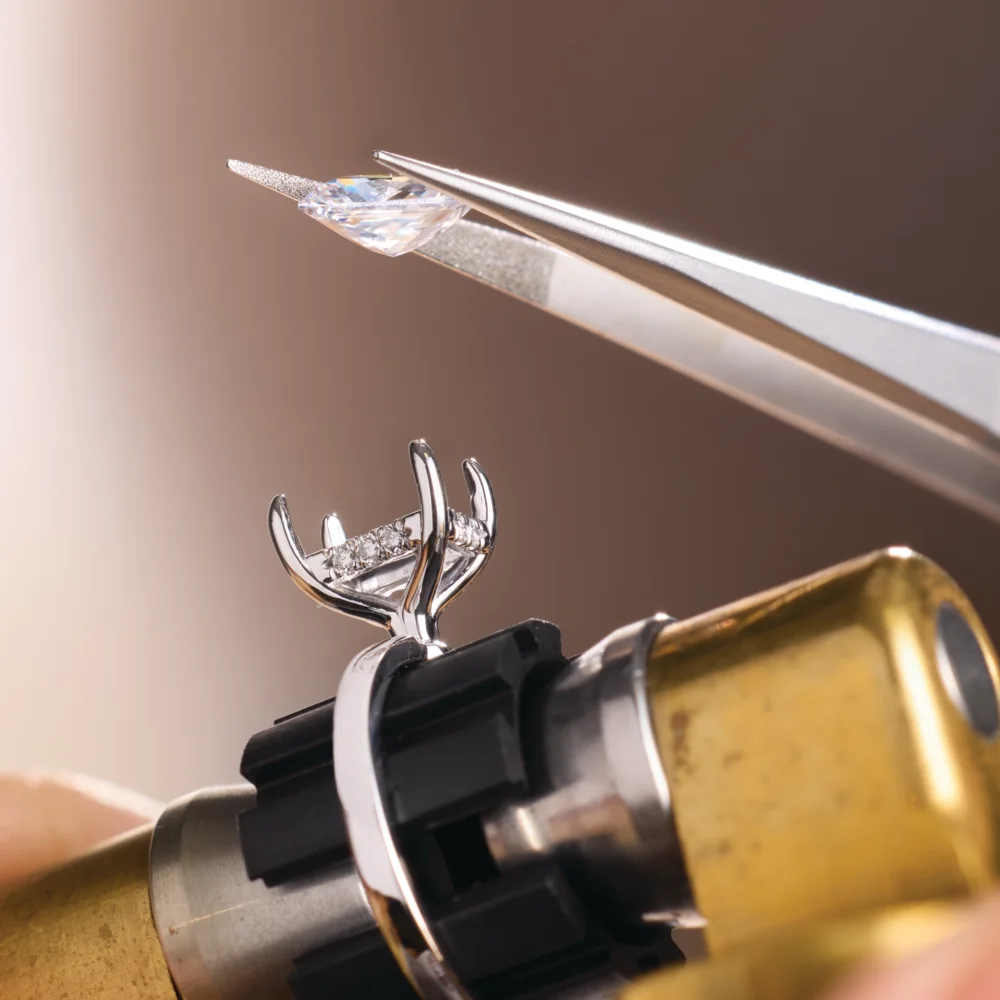

**5. Relevant** - `Ring Size Guide-616cb72dc1a458f6` | Ring Size Guide.pdf | pages [4]

This image features a detailed close-up of a silver ring with a diamond-studded cluster setting, placed on a ring mandrel for sizing. The ring features a round halo design surrounding a central stone, with smaller accent stones along the band. The background is slightly blurred, showing a green sticky note and a black frame. The image has a clean, professional look typical of a jewelry assessment or retail setting, with a subtle GIA.edu watermark in the lower right corner.

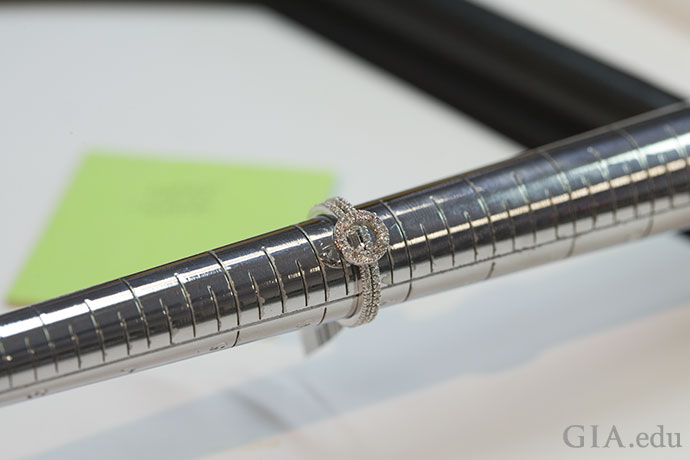

In [6]:
case_row = case_results.iloc[0]
display(Markdown(f"### {case_row['case_id']}: {case_row['query']}"))
print("Expected image IDs:", case_row["expected_image_ids"])
for rank, image_id in enumerate(case_row["retrieved_image_ids"], start=1):
    record = records_by_id[image_id]
    relevant = image_id in case_row["expected_image_ids"]
    display(Markdown(f"**{rank}. {'Relevant' if relevant else 'Not labeled relevant'}** - `{image_id}` | {record['file_name']} | pages {record.get('page_numbers', [])}\n\n{record.get('visual_description', '')}"))
    display(Image(filename=record["image_path"], width=180))

## 7. Release API client resources

In [7]:
if "image_model" in globals():
    del image_model
gc.collect()
print("Notebook 6 image retrieval evaluation complete.")

Notebook 6 image retrieval evaluation complete.
